In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, mean_absolute_error,
    confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)

# Load dataset
df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")
raw_count = len(df)

# 1. Clean: Drop rows with empty Review Text
df = df.dropna(subset=["Review Text"]).copy()
clean_count = len(df)
print(f"Raw rows: {raw_count} | After dropping missing Review Text: {clean_count} (Removed: {raw_count - clean_count})")

# 2. Merge Title and Review Text
df["full_text"] = df["Title"].fillna("") + " " + df["Review Text"].astype(str)
df["full_text"] = df["full_text"].str.strip()

# 3. Engineered numeric features
df["review_length"] = df["full_text"].str.len()
df["log_pos_feedback"] = np.log1p(df["Positive Feedback Count"].fillna(0))

# 4. Drop Recommended IND to prevent data leakage (Mandatory rule)
if "Recommended IND" in df.columns:
    df = df.drop(columns=["Recommended IND"])

# Fill missing categorical values with 'Unknown'
cat_cols = ["Division Name", "Department Name", "Class Name"]
for col in cat_cols:
    df[col] = df[col].fillna("Unknown")

print("\nMissing values after cleaning:\n", df[["full_text", "Age", "log_pos_feedback", "review_length"] + cat_cols].isnull().sum())
print("\nStar Rating Distribution:\n", df["Rating"].value_counts().sort_index())

Raw rows: 23486 | After dropping missing Review Text: 22641 (Removed: 845)

Missing values after cleaning:
 full_text           0
Age                 0
log_pos_feedback    0
review_length       0
Division Name       0
Department Name     0
Class Name          0
dtype: int64

Star Rating Distribution:
 Rating
1      821
2     1549
3     2823
4     4908
5    12540
Name: count, dtype: int64


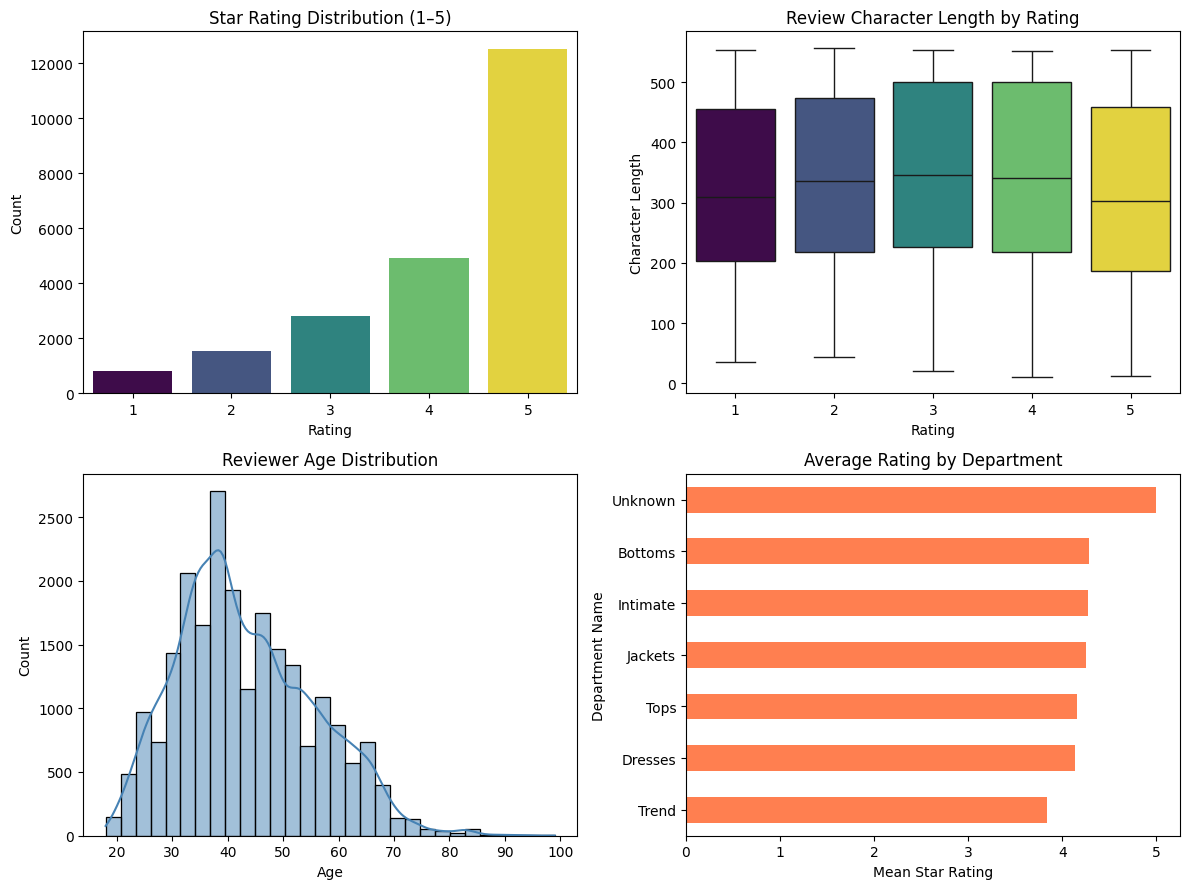

Mean Age: 43.28 | Median Review Length: 319.0


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Rating distribution
sns.countplot(data=df, x="Rating", hue="Rating", palette="viridis", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Star Rating Distribution (1–5)")
axes[0, 0].set_xlabel("Rating")
axes[0, 0].set_ylabel("Count")

# 2. Review length per rating
sns.boxplot(data=df, x="Rating", y="review_length", hue="Rating", palette="viridis", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Review Character Length by Rating")
axes[0, 1].set_xlabel("Rating")
axes[0, 1].set_ylabel("Character Length")

# 3. Age distribution
sns.histplot(df["Age"], bins=30, kde=True, color="steelblue", ax=axes[1, 0])
axes[1, 0].set_title("Reviewer Age Distribution")
axes[1, 0].set_xlabel("Age")

# 4. Ratings by Department
dept_rating = df.groupby("Department Name")["Rating"].mean().sort_values()
dept_rating.plot(kind="barh", color="coral", ax=axes[1, 1])
axes[1, 1].set_title("Average Rating by Department")
axes[1, 1].set_xlabel("Mean Star Rating")

plt.tight_layout()
plt.savefig("figures/b3_eda_plots.png", dpi=300)
plt.show()

print("Mean Age:", round(df["Age"].mean(), 2), "| Median Review Length:", df["review_length"].median())

In [4]:
num_cols = ["Age", "log_pos_feedback", "review_length"]
cat_cols = ["Division Name", "Department Name", "Class Name"]
text_col = "full_text"

X = df[num_cols + cat_cols + [text_col]]
y = df["Rating"].astype(int)

# Stratified 70/15/15 split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

# Preprocessor (fitted strictly on training data inside Pipeline)
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("txt", TfidfVectorizer(max_features=15000, ngram_range=(1, 2), stop_words="english"), text_col)
    ])

# Tune C for Logistic Regression on validation set
best_c, best_val_f1 = 1.0, 0.0
for c in [0.1, 0.5, 1.0, 2.0]:
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", LogisticRegression(C=c, max_iter=1000, random_state=SEED))])
    pipe.fit(X_train, y_train)
    val_f1 = f1_score(y_val, pipe.predict(X_val), average="macro")
    if val_f1 > best_val_f1:
        best_val_f1, best_c = val_f1, c
print(f"Tuned Logistic Regression C={best_c} (Val Macro-F1: {best_val_f1:.4f})")

# Compare 3 model families (with and without class_weight='balanced')
candidate_models = {
    "LogReg (Unweighted)": LogisticRegression(C=best_c, max_iter=1000, random_state=SEED),
    "LogReg (Balanced)": LogisticRegression(C=best_c, class_weight="balanced", max_iter=1000, random_state=SEED),
    "LinearSVC (Unweighted)": LinearSVC(C=0.5, random_state=SEED),
    "LinearSVC (Balanced)": LinearSVC(C=0.5, class_weight="balanced", random_state=SEED),
    "RandomForest (Unweighted)": RandomForestClassifier(n_estimators=150, max_depth=25, random_state=SEED, n_jobs=-1),
    "RandomForest (Balanced)": RandomForestClassifier(n_estimators=150, max_depth=25, class_weight="balanced", random_state=SEED, n_jobs=-1),
}

test_results = []
trained_pipes = {}

for name, clf in candidate_models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    pipe.fit(X_train, y_train)
    trained_pipes[name] = pipe

    preds = pipe.predict(X_test)
    recalls = recall_score(y_test, preds, average=None, labels=[1, 2, 3, 4, 5])
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Macro-F1": f1_score(y_test, preds, average="macro"),
        "Weighted-F1": f1_score(y_test, preds, average="weighted"),
        "Ordinal MAE": mean_absolute_error(y_test, preds),
        "Per-Class Recall (1..5)": [round(r, 3) for r in recalls]
    })

results_df = pd.DataFrame(test_results)
print("\n--- Test Set Model Comparison ---")
display(results_df.round(4))

Train: 15848 | Val: 3396 | Test: 3397
Tuned Logistic Regression C=2.0 (Val Macro-F1: 0.4290)

--- Test Set Model Comparison ---


,Model,Accuracy,Macro-F1,Weighted-F1,Ordinal MAE,Per-Class Recall (1..5)
0,LogReg (Unweighted),0.6420,0.4199,0.6128,0.4642,"[0.171, 0.168, 0.401, 0.336, 0.905]"
1,LogReg (Balanced),0.6226,0.4736,0.6313,0.4663,"[0.398, 0.328, 0.441, 0.463, 0.777]"
2,LinearSVC (Unweighted),0.6373,0.4177,0.6080,0.4681,"[0.195, 0.203, 0.347, 0.319, 0.91]"
3,LinearSVC (Balanced),0.6306,0.4476,0.6232,0.4598,"[0.276, 0.31, 0.422, 0.357, 0.847]"
4,RandomForest (Unweighted),0.5558,0.1494,0.3999,0.8066,"[0.0, 0.0, 0.017, 0.0, 1.0]"
5,RandomForest (Balanced),0.6082,0.4166,0.5880,0.5175,"[0.301, 0.237, 0.309, 0.307, 0.86]"


Best model selected for Ablation & Re-framing: LogReg (Balanced)

--- Mandatory Ablation Study (Test Set) ---


,Feature Set,Accuracy,Macro-F1,Weighted-F1,Ordinal MAE
0,Structured Only,0.2779,0.1981,0.3192,1.4698
1,Text Only,0.6200,0.4638,0.6288,0.4692
2,Combined (Struct + Text),0.6226,0.4736,0.6313,0.4663


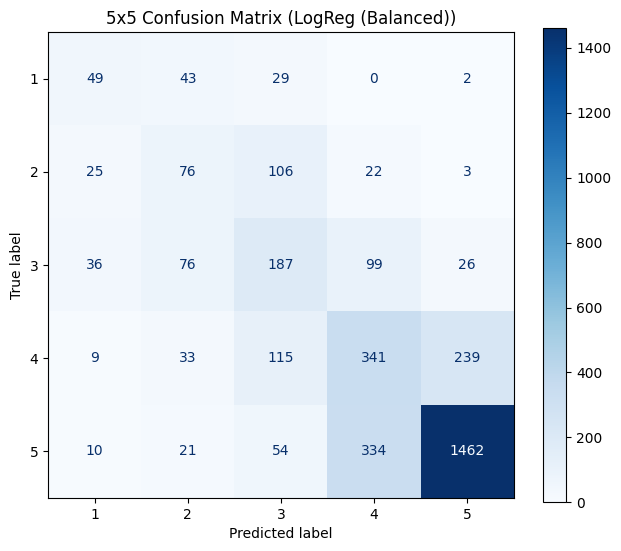

In [5]:
# Select best model by Macro-F1
best_model_name = results_df.sort_values(by="Macro-F1", ascending=False).iloc[0]["Model"]
print(f"Best model selected for Ablation & Re-framing: {best_model_name}")

# Helper to clone classifier with same params
from sklearn.base import clone
best_clf_template = candidate_models[best_model_name]

# 1. Structured-only preprocessor
prep_struct = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# 2. Text-only preprocessor
prep_text = ColumnTransformer([
    ("txt", TfidfVectorizer(max_features=15000, ngram_range=(1, 2), stop_words="english"), text_col)
])

# 3. Combined preprocessor
prep_comb = make_preprocessor()

ablation_rows = []
for mode, prep in [("Structured Only", prep_struct), ("Text Only", prep_text), ("Combined (Struct + Text)", prep_comb)]:
    pipe = Pipeline([("prep", prep), ("clf", clone(best_clf_template))])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    ablation_rows.append({
        "Feature Set": mode,
        "Accuracy": accuracy_score(y_test, preds),
        "Macro-F1": f1_score(y_test, preds, average="macro"),
        "Weighted-F1": f1_score(y_test, preds, average="weighted"),
        "Ordinal MAE": mean_absolute_error(y_test, preds)
    })

ablation_df = pd.DataFrame(ablation_rows)
print("\n--- Mandatory Ablation Study (Test Set) ---")
display(ablation_df.round(4))

# Save 5x5 Confusion Matrix for best combined model
best_pipe = trained_pipes[best_model_name]
y_pred_best = best_pipe.predict(X_test)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, labels=[1, 2, 3, 4, 5], cmap="Blues", ax=ax)
plt.title(f"5x5 Confusion Matrix ({best_model_name})")
plt.tight_layout()
plt.savefig("figures/b3_confusion_matrix.png", dpi=300)
plt.show()

In [6]:
# 1. Re-framing into 3 classes: Negative (1-2 -> 0), Neutral (3 -> 1), Positive (4-5 -> 2)
def map_3class(s):
    return s.map({1: 0, 2: 0, 3: 1, 4: 2, 5: 2})

y_train_3 = map_3class(y_train)
y_test_3 = map_3class(y_test)

pipe_3class = Pipeline([("prep", make_preprocessor()), ("clf", clone(best_clf_template))])
pipe_3class.fit(X_train, y_train_3)
preds_3 = pipe_3class.predict(X_test)

print("--- 3-Class Re-framing Results (Neg 1-2, Neu 3, Pos 4-5) ---")
print(f"Accuracy:    {accuracy_score(y_test_3, preds_3):.4f}")
print(f"Macro-F1:    {f1_score(y_test_3, preds_3, average='macro'):.4f}")
print(f"Weighted-F1: {f1_score(y_test_3, preds_3, average='weighted'):.4f}")

# 2. Show 3 misclassified reviews for error analysis
errors_df = X_test.copy()
errors_df["True_Rating"] = y_test
errors_df["Pred_Rating"] = y_pred_best
misclassified = errors_df[errors_df["True_Rating"] != errors_df["Pred_Rating"]]

print("\n--- 3 Sample Misclassified Reviews ---")
for idx, row in misclassified.sample(3, random_state=SEED).iterrows():
    print(f"True: {row['True_Rating']} | Pred: {row['Pred_Rating']} | Dept: {row['Department Name']}")
    print(f"Text: {row['full_text'][:220]}...\n")

--- 3-Class Re-framing Results (Neg 1-2, Neu 3, Pos 4-5) ---
Accuracy:    0.8119
Macro-F1:    0.6369
Weighted-F1: 0.8231

--- 3 Sample Misclassified Reviews ---
True: 3 | Pred: 4 | Dept: Bottoms
Text: Prob good if you're curvy Ordered these in 31p last year, prob could have worn a 30p, ordered 30p and 31p this year. the past couple of years the pilcro stet jeans in white fit me because they were cut straighter and not...

True: 4 | Pred: 3 | Dept: Jackets
Text: Cute jacket but low quality The jacket runs large so size down. it's a good jacket to throw on the go. but i don't see this lasting long bc after he first wash, it started piling. the quality of the material isn't great!...

True: 4 | Pred: 5 | Dept: Tops
Text: Nice and versatile Just received this and know i will get a lot of enjoyment from it. cute fit and since i have had something similar in the past, i know how versatile it is. nice soft material too!...

